# E-Commerce Purchase Intent Prediction using Explainable AI

# PART A — DATA ANALYSIS

In [258]:
%pip install lightgbm catboost xgboost plotly seaborn

# import liberries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    RobustScaler,
    FunctionTransformer
)

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import joblib

RANDOM_STATE = 42

Note: you may need to restart the kernel to use updated packages.


In [259]:
# Load the dataset
DATA_PATH = "ecommerce_sessions.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (12000, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Converted
0,1,14.6517,0,0.0000,19,283.8812,0.008014,0.042106,68.579222,0.0,June,1,2,1,1,Returning_Visitor,False,1
1,1,18.9189,2,54.9802,15,1241.7638,0.032395,0.058101,0.000000,0.0,May,2,1,8,12,Returning_Visitor,False,0
2,1,30.0198,0,0.0000,23,365.3384,0.006802,0.029451,0.000000,0.0,Mar,1,2,1,3,New_Visitor,True,0
3,1,6.5566,0,0.0000,6,687.4788,0.039577,0.104395,0.000000,0.6,Dec,1,1,1,2,Returning_Visitor,True,0
4,1,112.5842,1,36.3523,19,656.4535,0.004594,0.038321,0.000000,0.0,Mar,2,1,2,5,Returning_Visitor,False,0


In [260]:
# Besic dataset inspection
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget:")
print(df["Converted"].value_counts())

print("\nTarget percentage:")
print(df["Converted"].value_counts(normalize=True) * 100)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12000 non-null  int64  
 1   Administrative_Duration  12000 non-null  float64
 2   Informational            12000 non-null  int64  
 3   Informational_Duration   12000 non-null  float64
 4   ProductRelated           12000 non-null  int64  
 5   ProductRelated_Duration  12000 non-null  float64
 6   BounceRates              12000 non-null  float64
 7   ExitRates                12000 non-null  float64
 8   PageValues               12000 non-null  float64
 9   SpecialDay               12000 non-null  float64
 10  Month                    12000 non-null  object 
 11  OperatingSystems         12000 non-null  int64  
 12  Browser                  12000 non-null  int64  
 13  Region                   12000 non-null  int64  
 14  TrafficType           

In [261]:
conversion_rate = df["Converted"].mean() * 100

print(f"Conversion rate = {conversion_rate:.2f}%")

Conversion rate = 15.72%


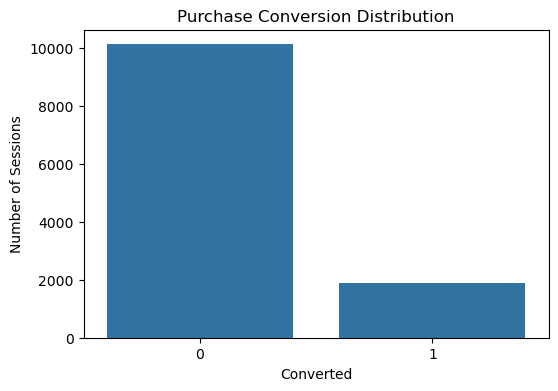

In [262]:
# Plot perches distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Converted"
)

plt.title("Purchase Conversion Distribution")
plt.xlabel("Converted")
plt.ylabel("Number of Sessions")

plt.show()

In [263]:
# compare buyers and non-buyers
important_features = [
    "PageValues",
    "BounceRates",
    "ExitRates",
    "ProductRelated",
    "ProductRelated_Duration"
]

buyer_comparison = (
    df.groupby("Converted")[important_features]
    .mean()
    .T
)

buyer_comparison

Converted,0,1
PageValues,5.081279,50.562025
BounceRates,0.023238,0.010391
ExitRates,0.058432,0.030894
ProductRelated,17.113902,34.408802
ProductRelated_Duration,624.718320,1250.669958


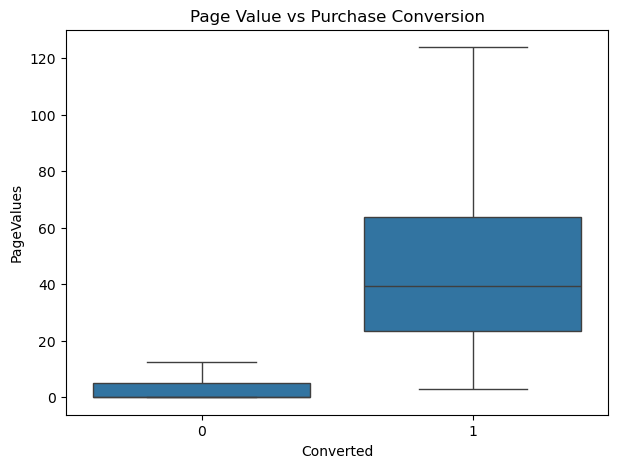

In [264]:
# page value vs conversion
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Converted",
    y="PageValues",
    showfliers=False
)

plt.title("Page Value vs Purchase Conversion")

plt.show()

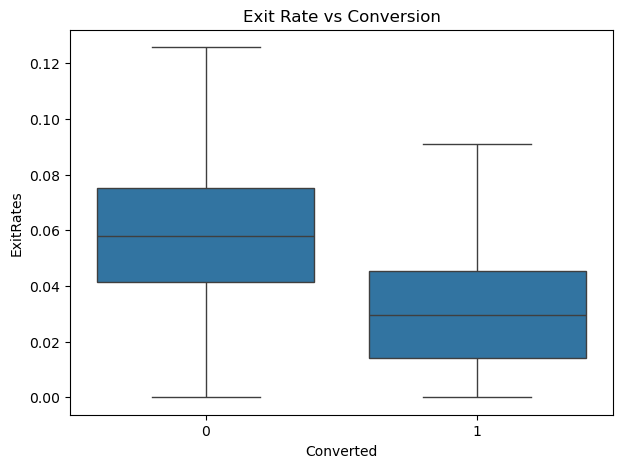

In [265]:
# Exit rate analysis

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Converted",
    y="ExitRates",
    showfliers=False
)

plt.title("Exit Rate vs Conversion")

plt.show()

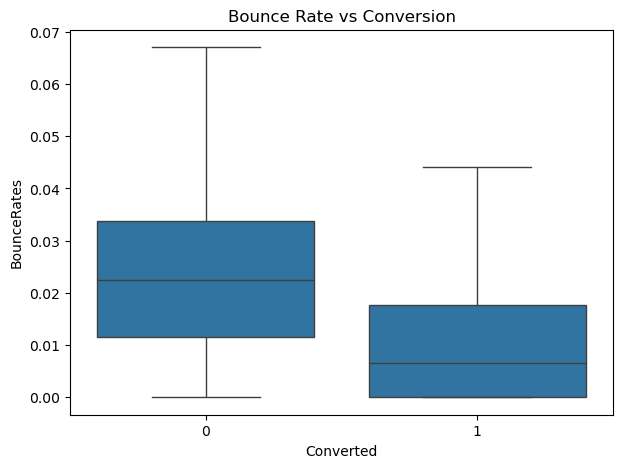

In [266]:
# Bounce rate analysis
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Converted",
    y="BounceRates",
    showfliers=False
)

plt.title("Bounce Rate vs Conversion")

plt.show()

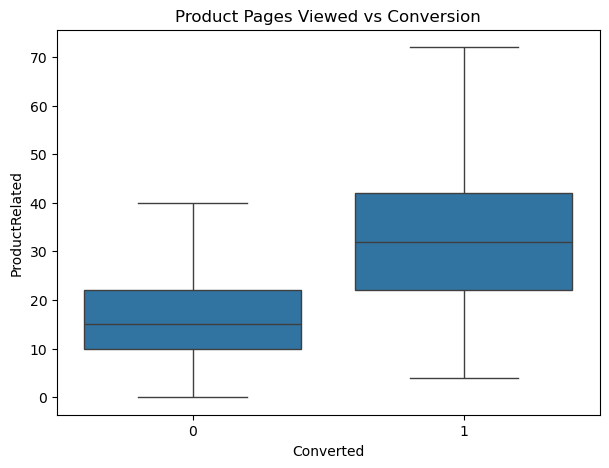

In [267]:
# porduct related engagment analysis
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Converted",
    y="ProductRelated",
    showfliers=False
)

plt.title("Product Pages Viewed vs Conversion")

plt.show()

In [268]:
# Visiter type analysis
visitor_conversion = (
    df.groupby("VisitorType")["Converted"]
    .agg(["mean", "count"])
    .reset_index()
)

visitor_conversion["conversion_rate"] = (
    visitor_conversion["mean"] * 100
)

visitor_conversion

,VisitorType,mean,count,conversion_rate
0,New_Visitor,0.101662,1564,10.166240
1,Other,0.150376,133,15.037594
2,Returning_Visitor,0.165680,10303,16.567990


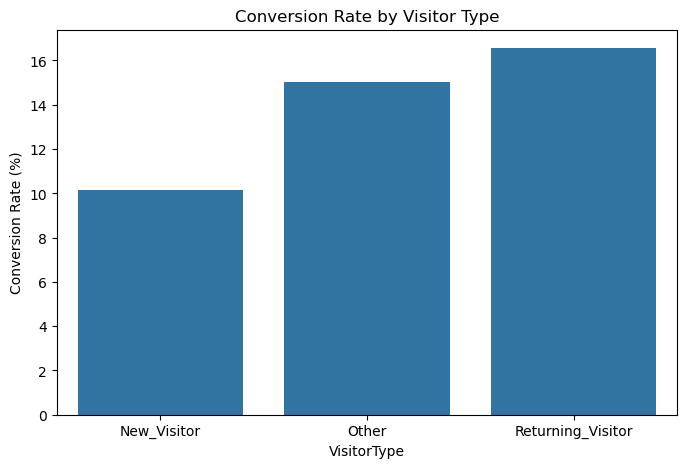

In [269]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=visitor_conversion,
    x="VisitorType",
    y="conversion_rate"
)

plt.ylabel("Conversion Rate (%)")
plt.title("Conversion Rate by Visitor Type")

plt.show()

In [270]:
# Monthly conversion analysis
month_conversion = (
    df.groupby("Month")["Converted"]
    .mean()
    .mul(100)
    .reset_index()
)

month_conversion.columns = [
    "Month",
    "ConversionRate"
]

month_conversion

,Month,ConversionRate
0,Aug,12.830189
1,Dec,17.942584
2,Feb,10.079576
3,Jul,12.500000
4,June,9.866221
5,Mar,13.873106
6,May,17.079347
7,Nov,20.000000
8,Oct,13.649025
9,Sep,11.833333


In [271]:
fig = px.bar(
    month_conversion,
    x="Month",
    y="ConversionRate",
    title="Monthly E-Commerce Conversion Rate",
    labels={
        "ConversionRate": "Conversion Rate (%)"
    }
)

fig.show()

In [272]:
# Weekend analysis
weekend_conversion = (
    df.groupby("Weekend")["Converted"]
    .mean() * 100
)

print(weekend_conversion)

Weekend
False    15.761460
True     15.569077
Name: Converted, dtype: float64


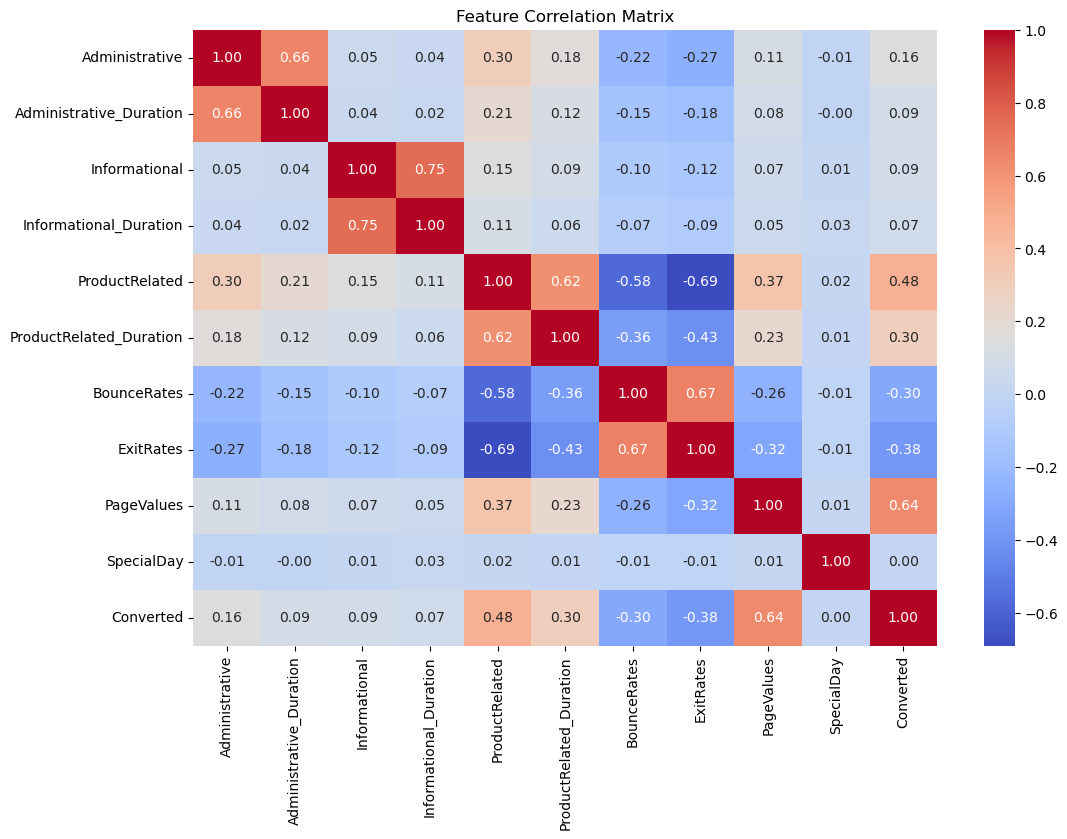

In [273]:
# corelation heatmap
continuous_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Converted"
]

corr = df[continuous_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

# PART B — FEATURE ENGINEERING

In [274]:
# create uesfull behavioral features
def create_features(data):
    
    data = data.copy()

    data["TotalPages"] = (
        data["Administrative"]
        + data["Informational"]
        + data["ProductRelated"]
    )

    data["TotalDuration"] = (
        data["Administrative_Duration"]
        + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )

    data["AvgTimePerPage"] = (
        data["TotalDuration"] /
        (data["TotalPages"] + 1)
    )

    data["ProductEngagementRatio"] = (
        data["ProductRelated"] /
        (data["TotalPages"] + 1)
    )

    data["ProductTimeRatio"] = (
        data["ProductRelated_Duration"] /
        (data["TotalDuration"] + 1)
    )

    data["ReturningVisitorFlag"] = (
        data["VisitorType"]
        .eq("Returning_Visitor")
        .astype(int)
    )

    return data

In [275]:
df_model = create_features(df)

print(df_model.shape)

df_model.head()

(12000, 24)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,TrafficType,VisitorType,Weekend,Converted,TotalPages,TotalDuration,AvgTimePerPage,ProductEngagementRatio,ProductTimeRatio,ReturningVisitorFlag
0,1,14.6517,0,0.0000,19,283.8812,0.008014,0.042106,68.579222,0.0,...,1,Returning_Visitor,False,1,20,298.5329,14.215852,0.904762,0.947746,1
1,1,18.9189,2,54.9802,15,1241.7638,0.032395,0.058101,0.000000,0.0,...,12,Returning_Visitor,False,0,18,1315.6629,69.245416,0.789474,0.943114,1
2,1,30.0198,0,0.0000,23,365.3384,0.006802,0.029451,0.000000,0.0,...,3,New_Visitor,True,0,24,395.3582,15.814328,0.920000,0.921738,0
3,1,6.5566,0,0.0000,6,687.4788,0.039577,0.104395,0.000000,0.6,...,2,Returning_Visitor,True,0,7,694.0354,86.754425,0.750000,0.989128,1
4,1,112.5842,1,36.3523,19,656.4535,0.004594,0.038321,0.000000,0.0,...,5,Returning_Visitor,False,0,21,805.3900,36.608636,0.863636,0.814065,1


# PART C — TRAIN/TEST SPLIT

In [276]:
# Define x and y
X = df_model.drop(columns=["Converted"])

y = df_model["Converted"]

y = df_model["Converted"]

In [277]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("Train conversion:", y_train.mean())
print("Test conversion :", y_test.mean())

Train: (9600, 23)
Test : (2400, 23)
Train conversion: 0.1571875
Test conversion : 0.15708333333333332


In [278]:
stratify=y

# PART D — CORRECT PREPROCESSING

In [279]:
# Dfine catagorical variables
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

In [280]:
# Numarical variables
numeric_features = [
    col
    for col in X_train.columns
    if col not in categorical_features
]

In [281]:
print("Numeric:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

Numeric:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'TotalPages', 'TotalDuration', 'AvgTimePerPage', 'ProductEngagementRatio', 'ProductTimeRatio', 'ReturningVisitorFlag']

Categorical:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


In [282]:
# Build prprocessing pipelines
numeric_pipeline = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",RobustScaler())])

In [283]:
categorical_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )

])

In [284]:
preprocessor = ColumnTransformer([

    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),

    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )

])

# PART E — SIX ML MODELS

In [285]:
# Define models
# Logistic Regression
logistic = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

In [286]:
# Decision Tree
decision_tree = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE
)

In [287]:
# Random Forest
random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [288]:
# XGBoost
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print(scale_pos_weight)

5.361829025844931


In [289]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE
)

In [290]:
# LightGBM
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    verbosity=-1
)

In [291]:
# CatBoost
catboost = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    auto_class_weights="Balanced",
    verbose=0,
    random_seed=RANDOM_STATE
)

In [292]:
# create model dictionary
models = {

    "Logistic Regression": logistic,

    "Decision Tree": decision_tree,

    "Random Forest": random_forest,

    "XGBoost": xgb,

    "LightGBM": lgbm,

    "CatBoost": catboost

}

In [293]:
# train and evaluate models
results = []

trained_models = {}

for name, model in models.items():

    print(f"\nTraining: {name}")

    pipeline = Pipeline([

        ("preprocessor", preprocessor),

        ("model", model)

    ])

    pipeline.fit(
        X_train,
        y_train
    )

    predictions = pipeline.predict(X_test)

    probabilities = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions
    )

    f1 = f1_score(
        y_test,
        predictions
    )

    roc_auc = roc_auc_score(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )

    results.append({

        "Model": name,

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1": f1,

        "ROC-AUC": roc_auc,

        "PR-AUC": pr_auc

    })

    trained_models[name] = pipeline


Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Training: XGBoost

Training: LightGBM

Training: CatBoost


In [294]:
# create model comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
5,CatBoost,0.905000,0.635209,0.928382,0.754310,0.971882,0.861999
3,XGBoost,0.915000,0.669276,0.907162,0.770270,0.970276,0.849225
2,Random Forest,0.925000,0.840830,0.644562,0.729730,0.966207,0.835824
4,LightGBM,0.915000,0.681342,0.862069,0.761124,0.967304,0.835712
0,Logistic Regression,0.909583,0.652672,0.907162,0.759156,0.965147,0.801457
1,Decision Tree,0.898333,0.679245,0.668435,0.673797,0.804806,0.506115


In [295]:
# plot model compretion
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "ROC-AUC",
        "PR-AUC",
        "Recall",
        "F1"
    ],
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    plot_df,
    x="Model",
    y="Score",
    color="Metric",
    barmode="group",
    title="Machine Learning Model Comparison"
)

fig.show()

# PART F — CONFUSION MATRIX

In [296]:
# select the best model based on PR-AUC
best_model_name = results_df.iloc[0]["Model"]

print(
    "Best model:",
    best_model_name
)

best_model = trained_models[
    best_model_name
]

Best model: CatBoost


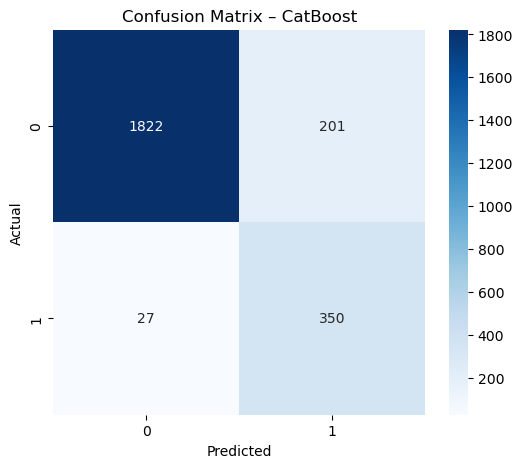

In [297]:
# confusion matrix for the best model
best_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    best_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    f"Confusion Matrix – {best_model_name}"
)

plt.show()

# PART G — ROC CURVE

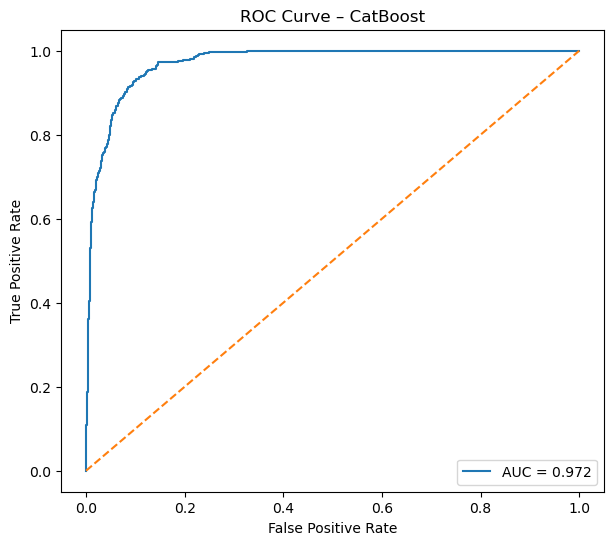

In [298]:
# plot Roc
best_prob = best_model.predict_proba(
    X_test
)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    best_prob
)

roc_auc = roc_auc_score(
    y_test,
    best_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve – {best_model_name}"
)

plt.legend()

plt.show()

# PART H — PRECISION-RECALL CURVE

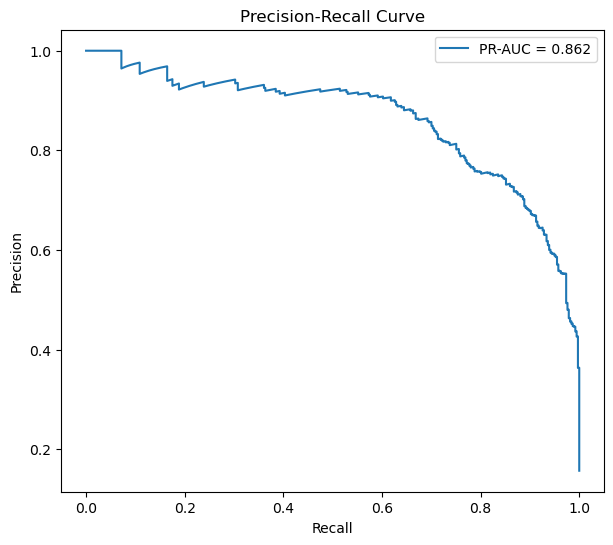

In [299]:
precision, recall, thresholds_pr = (
    precision_recall_curve(
        y_test,
        best_prob
    )
)

pr_auc = average_precision_score(
    y_test,
    best_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {pr_auc:.3f}"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve"
)

plt.legend()

plt.show()

# PART I — BUSINESS THRESHOLD

In [300]:
threshold_results = []

for threshold in np.arange(
    0.10,
    0.91,
    0.05
):

    predictions = (
        best_prob >= threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions
        ),

        "F1": f1_score(
            y_test,
            predictions
        )

    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.476744,0.978780,0.641182
1,0.15,0.505510,0.973475,0.665458
2,0.20,0.528818,0.973475,0.685341
3,0.25,0.550225,0.973475,0.703065
4,0.30,0.566719,0.957560,0.712032
5,0.35,0.589786,0.949602,0.727642
6,0.40,0.601019,0.938992,0.732919
7,0.45,0.616056,0.936340,0.743158
8,0.50,0.635209,0.928382,0.754310
9,0.55,0.648496,0.915119,0.759076


In [301]:
# Select best F1 threshold
best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

BEST_THRESHOLD = best_row["Threshold"]

print(
    "Best threshold:",
    BEST_THRESHOLD
)

print(best_row)

Best threshold: 0.7000000000000002
Threshold    0.700000
Precision    0.728700
Recall       0.862069
F1           0.789793
Name: 12, dtype: float64


# PART J — VERY IMPORTANT PAGEVALUES ABLATION

In [302]:
# -----------------------------------------
# PAGEVALUES ABLATION TEST
# -----------------------------------------

# Define categorical columns again
categorical_features_np = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

X_train_np = X_train.drop(columns=["PageValues"], errors="ignore")
X_test_np = X_test.drop(columns=["PageValues"], errors="ignore")

numeric_features_np = [
    col for col in X_train_np.columns
    if col not in categorical_features_np
]

# Numeric preprocessing
numeric_pipeline_np = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical preprocessing
categorical_pipeline_np = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor_np = ColumnTransformer([
    ("numeric", numeric_pipeline_np, numeric_features_np),
    ("categorical", categorical_pipeline_np, categorical_features_np)
])

# CatBoost without PageValues
catboost_np = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    auto_class_weights="Balanced",
    verbose=0,
    random_seed=42
)

model_without_pagevalues = Pipeline([
    ("preprocessor", preprocessor_np),
    ("model", catboost_np)
])

model_without_pagevalues.fit(X_train_np, y_train)

prob_np = model_without_pagevalues.predict_proba(X_test_np)[:, 1]
pred_np = model_without_pagevalues.predict(X_test_np)

roc_np = roc_auc_score(y_test, prob_np)
pr_np = average_precision_score(y_test, prob_np)
recall_np = recall_score(y_test, pred_np)
f1_np = f1_score(y_test, pred_np)

print("Without PageValues")
print("ROC-AUC:", round(roc_np, 4))
print("PR-AUC:", round(pr_np, 4))
print("Recall:", round(recall_np, 4))
print("F1:", round(f1_np, 4))

Without PageValues
ROC-AUC: 0.848
PR-AUC: 0.5595
Recall: 0.7294
F1: 0.5335


In [303]:
ablation_results = pd.DataFrame({

    "Model Version": [
        "With PageValues",
        "Without PageValues"
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, best_prob),
        roc_np
    ],

    "PR-AUC": [
        average_precision_score(y_test, best_prob),
        pr_np
    ],

    "Recall": [
        recall_score(y_test, best_pred),
        recall_np
    ],

    "F1": [
        f1_score(y_test, best_pred),
        f1_np
    ]

})

ablation_results

,Model Version,ROC-AUC,PR-AUC,Recall,F1
0,With PageValues,0.971882,0.861999,0.928382,0.754310
1,Without PageValues,0.847957,0.559536,0.729443,0.533463


In [304]:
final_pred = (
    best_prob >= BEST_THRESHOLD
).astype(int)

print(
    classification_report(
        y_test,
        final_pred
    )
)

print(
    "Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        final_pred
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_test,
            best_prob
        ),
        4
    )
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_test,
            best_prob
        ),
        4
    )
)

              precision    recall  f1-score   support

           0       0.97      0.94      0.96      2023
           1       0.73      0.86      0.79       377

    accuracy                           0.93      2400
   macro avg       0.85      0.90      0.87      2400
weighted avg       0.93      0.93      0.93      2400

Confusion Matrix:
[[1902  121]
 [  52  325]]
ROC-AUC: 0.9719
PR-AUC: 0.862


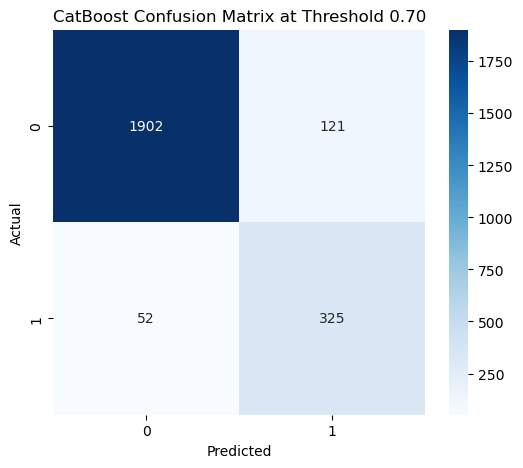

In [305]:
cm_final = confusion_matrix(
    y_test,
    final_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "CatBoost Confusion Matrix at Threshold 0.70"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

In [306]:
import shap

# Add feature importance summary 
# Compute SHAP values only if they are not already available
if "shap_values" not in globals():

    preprocessor_fitted = best_model.named_steps["preprocessor"]
    model_fitted = best_model.named_steps["model"]

    X_test_transformed = preprocessor_fitted.transform(X_test)

    explainer = shap.TreeExplainer(model_fitted)
    shap_values = explainer.shap_values(X_test_transformed[:500])

# For binary classification SHAP can come back as a list of arrays
if isinstance(shap_values, list):
    shap_values = np.asarray(
        shap_values[1] if len(shap_values) > 1 else shap_values[0]
    )

mean_abs_shap = np.abs(shap_values).mean(axis=0)

feature_names = preprocessor_fitted.get_feature_names_out()

global_shap_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_abs_SHAP": mean_abs_shap
})

global_shap_df = (
    global_shap_df
    .sort_values(
        "Mean_abs_SHAP",
        ascending=False
    )
    .head(15)
)

global_shap_df

,Feature,Mean_abs_SHAP
8,numeric__PageValues,3.850545
10,numeric__TotalPages,0.360913
7,numeric__ExitRates,0.271239
4,numeric__ProductRelated,0.266433
6,numeric__BounceRates,0.216970
11,numeric__TotalDuration,0.168056
1,numeric__Administrative_Duration,0.116334
12,numeric__AvgTimePerPage,0.106898
5,numeric__ProductRelated_Duration,0.095048
13,numeric__ProductEngagementRatio,0.077210


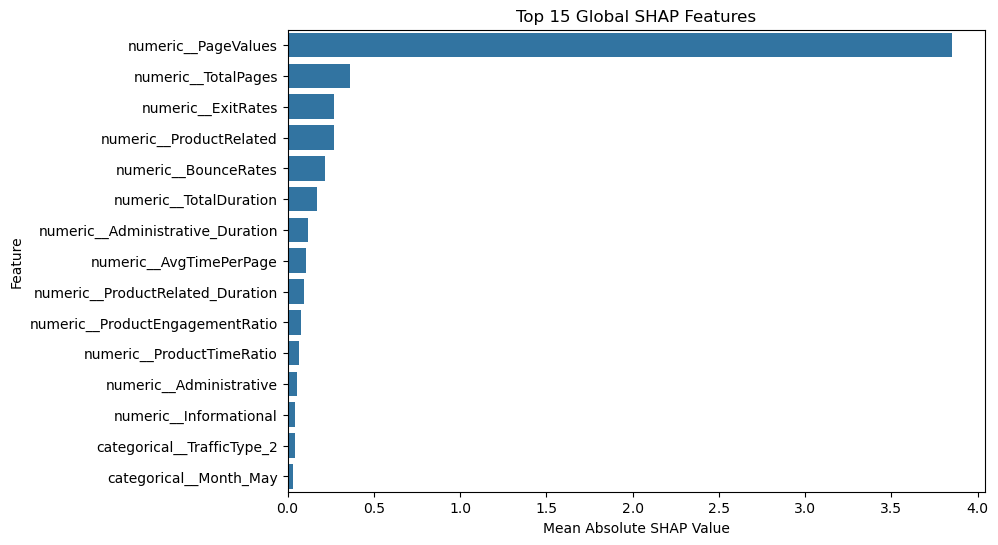

In [307]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=global_shap_df,
    x="Mean_abs_SHAP",
    y="Feature"
)

plt.title(
    "Top 15 Global SHAP Features"
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Feature"
)

plt.show()

# PART K — SAVE THE MODEL

In [308]:
# Save complet pipline
import os

os.makedirs(
    "../artifacts",
    exist_ok=True
)

joblib.dump(
    best_model,
    "../artifacts/purchase_intent_model.joblib"
)

print("Model saved.")

Model saved.


In [309]:
joblib.dump(
    BEST_THRESHOLD,
    "../artifacts/decision_threshold.joblib"
)

['../artifacts/decision_threshold.joblib']

# PART L — LOAD AND PREDICT

In [310]:
# Test the saved model
loaded_model = joblib.load(
    "../artifacts/purchase_intent_model.joblib"
)

threshold = joblib.load(
    "../artifacts/decision_threshold.joblib"
)

In [311]:
sample = X_test.iloc[[0]]

sample

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,TotalPages,TotalDuration,AvgTimePerPage,ProductEngagementRatio,ProductTimeRatio,ReturningVisitorFlag
5015,0,0.0,0,0.0,8,481.1911,0.024147,0.078267,0.0,0.0,...,1,3,Returning_Visitor,False,8,481.1911,53.465678,0.888889,0.997926,1


In [312]:
sample_raw = X_test.iloc[[0]]

probability = loaded_model.predict_proba(sample_raw)[0, 1]

prediction = int(probability >= threshold)

print("Purchase probability:", round(probability, 4))
print("Prediction:", prediction)

prediction = int(
    probability >= threshold
)

print(
    "Purchase probability:",
    round(probability, 4)
)

print(
    "Prediction:",
    prediction
)

Purchase probability: 0.0011
Prediction: 0
Purchase probability: 0.0011
Prediction: 0


# PART M — SHAP EXPLAINABILITY

In [313]:

%pip install shap
import shap


Note: you may need to restart the kernel to use updated packages.


In [314]:
preprocessor_fitted = (
    best_model.named_steps[
        "preprocessor"
    ]
)

model_fitted = (
    best_model.named_steps[
        "model"
    ]
)

In [315]:
# trasform
X_train_transformed = (
    preprocessor_fitted.transform(
        X_train
    )
)

X_test_transformed = (
    preprocessor_fitted.transform(
        X_test
    )
)

In [316]:
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

In [317]:
# tree based winig model
explainer = shap.TreeExplainer(
    model_fitted
)

shap_values = explainer.shap_values(
    X_test_transformed[:500]
)

In [318]:
# Global Explanation
explainer = shap.TreeExplainer(
    model_fitted
)

shap_values = explainer.shap_values(
    X_test_transformed[:500]
)

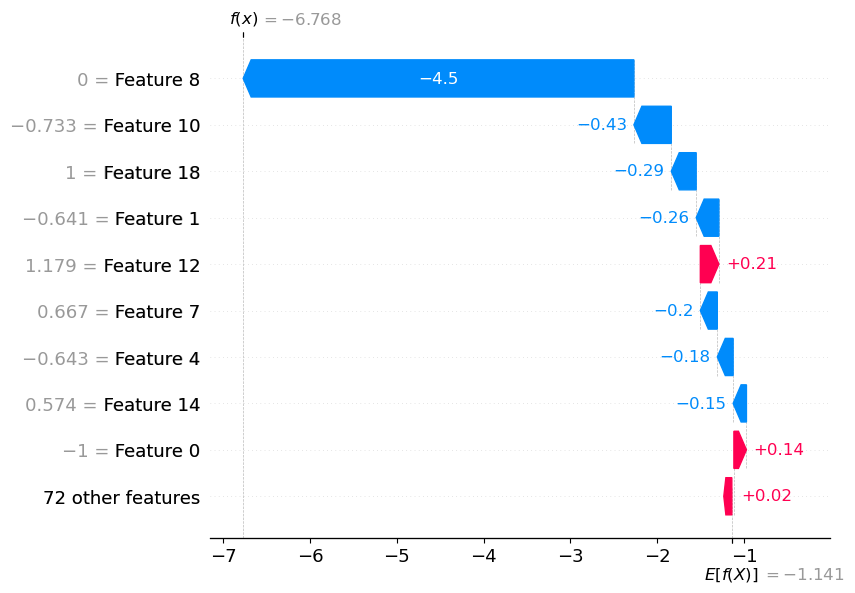

In [319]:
# indivisual shape explination
sample_index = 0

explanation = explainer(
    X_test_transformed[sample_index:sample_index+1]
)

shap.plots.waterfall(
    explanation[0]
)

In [320]:
# Get transformed feature names
feature_names = preprocessor_fitted.get_feature_names_out()

# One sample explanation
sample_index = 0

explanation = explainer(
    X_test_transformed[sample_index:sample_index+1]
)

single_exp = explanation[0]

# Build table using actual feature names
shap_df = pd.DataFrame({
    "Feature": feature_names,
    "Feature_value": single_exp.data,
    "SHAP_value": single_exp.values
})

# Sort by importance
shap_df["abs_SHAP"] = shap_df["SHAP_value"].abs()

top_features = (
    shap_df
    .sort_values("abs_SHAP", ascending=False)
    .head(10)
)

print(
    top_features[
        ["Feature", "Feature_value", "SHAP_value"]
    ]
)

                             Feature  Feature_value  SHAP_value
8                numeric__PageValues       0.000000   -4.499996
10               numeric__TotalPages      -0.733333   -0.430431
18            categorical__Month_Feb       1.000000   -0.286952
1   numeric__Administrative_Duration      -0.640776   -0.261259
12           numeric__AvgTimePerPage       1.179495    0.213544
7                 numeric__ExitRates       0.667377   -0.195428
4            numeric__ProductRelated      -0.642857   -0.182380
14         numeric__ProductTimeRatio       0.574067   -0.153158
0            numeric__Administrative      -1.000000    0.144428
11            numeric__TotalDuration      -0.116873   -0.094622


# PART N — LIME

In [321]:
%pip install lime
from lime.lime_tabular import (
    LimeTabularExplainer
)

Note: you may need to restart the kernel to use updated packages.


In [322]:
import numpy as np
from lime.lime_tabular import LimeTabularExplainer

# Convert transformed training data to dense array if needed
if hasattr(X_train_transformed, "toarray"):
    X_train_lime = X_train_transformed.toarray()
else:
    X_train_lime = np.asarray(X_train_transformed)

if hasattr(X_test_transformed, "toarray"):
    X_test_lime = X_test_transformed.toarray()
else:
    X_test_lime = np.asarray(X_test_transformed)

print("Train shape:", X_train_lime.shape)
print("Test shape:", X_test_lime.shape)
print("Number of features:", len(feature_names))

Train shape: (9600, 81)
Test shape: (2400, 81)
Number of features: 81


In [323]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime,
    feature_names=list(feature_names),
    class_names=["No Purchase", "Purchase"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

In [324]:
sample_index = 0

sample = X_test_lime[sample_index]

print("Sample shape:", sample.shape)

Sample shape: (81,)


In [325]:
lime_result = lime_explainer.explain_instance(
    data_row=sample,
    predict_fn=model_fitted.predict_proba,
    num_features=10
)

In [326]:
for feature, weight in lime_result.as_list():
    print(f"{feature}: {weight:.4f}")

numeric__PageValues <= 0.00: -0.4941
categorical__Browser_13 <= 0.00: -0.1493
categorical__Browser_9 <= 0.00: 0.0724
categorical__VisitorType_Other <= 0.00: 0.0601
numeric__ExitRates > 0.50: -0.0514
categorical__Browser_7 <= 0.00: 0.0495
categorical__TrafficType_2 <= 0.00: 0.0442
categorical__Month_Feb > 0.00: -0.0422
categorical__Browser_5 <= 0.00: -0.0404
categorical__Browser_4 <= 0.00: 0.0339


### LIME Interpretation

For this individual session, LIME indicates that low PageValues had the strongest negative effect on purchase probability. Higher ExitRates and the February session also reduced the likelihood of conversion. These findings are consistent with the SHAP explanation, increasing confidence that the model is using meaningful behavioral signals.

# PART O — FASTAPI

In [327]:
import os
import joblib

PROJECT_DIR = r"D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction"

ARTIFACT_DIR = os.path.join(PROJECT_DIR, "artifacts")

os.makedirs(ARTIFACT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "purchase_intent_model.joblib"
)

THRESHOLD_PATH = os.path.join(
    ARTIFACT_DIR,
    "decision_threshold.joblib"
)

joblib.dump(best_model, MODEL_PATH)
joblib.dump(BEST_THRESHOLD, THRESHOLD_PATH)

print("Saved model to:")
print(MODEL_PATH)

print("\nSaved threshold to:")
print(THRESHOLD_PATH)

Saved model to:
D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction\artifacts\purchase_intent_model.joblib

Saved threshold to:
D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction\artifacts\decision_threshold.joblib


In [328]:
import joblib

model = joblib.load(
    r"D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction\artifacts\purchase_intent_model.joblib"
)

threshold = joblib.load(
    r"D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction\artifacts\decision_threshold.joblib"
)

print("Model loaded successfully")
print("Threshold:", threshold)

Model loaded successfully
Threshold: 0.7000000000000002


In [329]:
from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib
import os


# ---------------------------
# Paths
# ---------------------------

PROJECT_DIR = r"D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "artifacts",
    "purchase_intent_model.joblib"
)

THRESHOLD_PATH = os.path.join(
    PROJECT_DIR,
    "artifacts",
    "decision_threshold.joblib"
)


# ---------------------------
# Load model
# ---------------------------

model = joblib.load(MODEL_PATH)
threshold = joblib.load(THRESHOLD_PATH)


# ---------------------------
# FastAPI application
# ---------------------------

app = FastAPI(
    title="E-Commerce Purchase Intent Prediction API",
    version="1.0"
)


# ---------------------------
# Input schema
# MUST come before predict()
# ---------------------------

class SessionData(BaseModel):

    Administrative: int
    Administrative_Duration: float

    Informational: int
    Informational_Duration: float

    ProductRelated: int
    ProductRelated_Duration: float

    BounceRates: float
    ExitRates: float
    PageValues: float

    SpecialDay: float

    Month: str

    OperatingSystems: int
    Browser: int
    Region: int
    TrafficType: int

    VisitorType: str
    Weekend: bool


# ---------------------------
# Health endpoint
# ---------------------------

@app.get("/health")
def health():

    return {
        "status": "healthy",
        "model_loaded": True,
        "threshold": round(float(threshold), 2)
    }


# ---------------------------
# Prediction endpoint
# ---------------------------

@app.post("/predict")
def predict(session: SessionData):

    data = pd.DataFrame(
        [session.model_dump()]
    )

    # Feature engineering

    data["TotalPages"] = (
        data["Administrative"]
        + data["Informational"]
        + data["ProductRelated"]
    )

    data["TotalDuration"] = (
        data["Administrative_Duration"]
        + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )

    data["AvgTimePerPage"] = (
        data["TotalDuration"]
        / (data["TotalPages"] + 1)
    )

    data["ProductEngagementRatio"] = (
        data["ProductRelated"]
        / (data["TotalPages"] + 1)
    )

    data["ProductTimeRatio"] = (
        data["ProductRelated_Duration"]
        / (data["TotalDuration"] + 1)
    )

    data["ReturningVisitorFlag"] = (
        data["VisitorType"]
        .eq("Returning_Visitor")
        .astype(int)
    )

    # Prediction

    probability = model.predict_proba(data)[0, 1]

    prediction = int(
        probability >= threshold
    )

    label = (
        "Likely to Purchase"
        if prediction == 1
        else "Unlikely to Purchase"
    )

    return {
        "prediction": prediction,
        "label": label,
        "purchase_probability": round(float(probability), 4),
        "purchase_probability_percent": round(float(probability) * 100, 2),
        "decision_threshold": round(float(threshold), 2)
    }

# PART P — STREAMLIT DASHBOARD

In [330]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os
import plotly.express as px

PROJECT_DIR = r"D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction"

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "dataset",
    "ecommerce_sessions.csv"
)

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "artifacts",
    "purchase_intent_model.joblib"
)

THRESHOLD_PATH = os.path.join(
    PROJECT_DIR,
    "artifacts",
    "decision_threshold.joblib"
)

st.set_page_config(
    page_title="E-Commerce Purchase Intent Prediction",
    layout="wide"
)

model = joblib.load(MODEL_PATH)
threshold = joblib.load(THRESHOLD_PATH)

if not os.path.isfile(DATA_PATH):
    csv_candidates = []

    for root, _, files in os.walk(PROJECT_DIR):
        csv_candidates.extend(
            os.path.join(root, filename)
            for filename in files
            if filename.lower().endswith(".csv")
        )

    exact_match = [
        path for path in csv_candidates
        if os.path.basename(path).lower() == "ecommerce_sessions.csv"
    ]

    dataset_matches = [
        path for path in csv_candidates
        if os.path.basename(os.path.dirname(path)).lower() == "dataset"
    ]

    if exact_match:
        DATA_PATH = exact_match[0]
    elif dataset_matches:
        DATA_PATH = dataset_matches[0]
    elif csv_candidates:
        DATA_PATH = csv_candidates[0]
    else:
        st.error(
            "No CSV file was found in the project folder. "
            "Place the dataset in the project or update DATA_PATH."
        )
        st.stop()

df = pd.read_csv(DATA_PATH)

st.title("🛒 E-Commerce Purchase Intent Prediction")

st.write(
    "Machine-learning dashboard for predicting whether a visitor is likely to make a purchase."
)

2026-10-05 06:42:28.933 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.459 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.459 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.460 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.461 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.461 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.462 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [331]:
# Add dashbord KPIs
col1, col2, col3 = st.columns(3)

col1.metric(
    "Total Sessions",
    f"{len(df):,}"
)

col2.metric(
    "Purchases",
    f"{df['Converted'].sum():,}"
)

col3.metric(
    "Conversion Rate",
    f"{df['Converted'].mean()*100:.2f}%"
)

2026-10-05 06:42:29.475 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.476 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.477 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.479 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.480 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.481 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.482 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.485 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [332]:
# Add conversion chart
conversion_counts = (
    df["Converted"]
    .value_counts()
    .rename_axis("Converted")
    .reset_index(name="Count")
)

conversion_counts["Status"] = conversion_counts["Converted"].map({
    0: "No Purchase",
    1: "Purchase"
})

fig = px.bar(
    conversion_counts,
    x="Status",
    y="Count",
    title="Purchase Conversion Distribution"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

2026-10-05 06:42:29.553 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-05 06:42:29.556 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.557 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.558 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.558 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-05 06:42:29.559 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [333]:
# Add visitoer type analysis
visitor_conversion = (
    df.groupby("VisitorType")["Converted"]
    .mean()
    .mul(100)
    .reset_index()
)

visitor_conversion.columns = [
    "VisitorType",
    "ConversionRate"
]

fig = px.bar(
    visitor_conversion,
    x="VisitorType",
    y="ConversionRate",
    title="Conversion Rate by Visitor Type"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

2026-10-05 06:42:29.619 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-05 06:42:29.623 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.624 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.624 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.625 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-05 06:42:29.625 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [334]:
# Add monthly analysis
monthly = (
    df.groupby("Month")["Converted"]
    .mean()
    .mul(100)
    .reset_index()
)

monthly.columns = [
    "Month",
    "ConversionRate"
]

fig = px.bar(
    monthly,
    x="Month",
    y="ConversionRate",
    title="Monthly Conversion Rate"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

2026-10-05 06:42:29.694 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-05 06:42:29.696 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.697 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.698 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [335]:
st.header("Live Purchase Prediction")

2026-10-05 06:42:29.711 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.713 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.714 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [336]:
administrative = st.number_input(
    "Administrative pages",
    min_value=0,
    value=0
)

administrative_duration = st.number_input(
    "Administrative duration",
    min_value=0.0,
    value=0.0
)

informational = st.number_input(
    "Informational pages",
    min_value=0,
    value=0
)

informational_duration = st.number_input(
    "Informational duration",
    min_value=0.0,
    value=0.0
)

product_related = st.number_input(
    "Product-related pages",
    min_value=0,
    value=10
)

product_related_duration = st.number_input(
    "Product-related duration",
    min_value=0.0,
    value=300.0
)

bounce_rates = st.number_input(
    "Bounce rate",
    min_value=0.0,
    max_value=1.0,
    value=0.02
)

exit_rates = st.number_input(
    "Exit rate",
    min_value=0.0,
    max_value=1.0,
    value=0.04
)

page_values = st.number_input(
    "Page values",
    min_value=0.0,
    value=5.0
)

2026-10-05 06:42:29.750 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.752 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.754 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.755 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.756 Session state does not function when running a script without `streamlit run`
2026-10-05 06:42:29.758 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.759 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.760 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42

In [337]:
special_day = st.number_input(
    "Special day",
    min_value=0.0,
    max_value=1.0,
    value=0.0
)

month = st.selectbox(
    "Month",
    sorted(df["Month"].unique())
)

operating_system = st.selectbox(
    "Operating system",
    sorted(df["OperatingSystems"].unique())
)

browser = st.selectbox(
    "Browser",
    sorted(df["Browser"].unique())
)

region = st.selectbox(
    "Region",
    sorted(df["Region"].unique())
)

traffic_type = st.selectbox(
    "Traffic type",
    sorted(df["TrafficType"].unique())
)

visitor_type = st.selectbox(
    "Visitor type",
    sorted(df["VisitorType"].unique())
)

weekend = st.checkbox(
    "Weekend"
)

2026-10-05 06:42:29.902 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.903 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.904 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.905 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.906 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.906 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.907 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.908 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [338]:
# Addd prediction
if st.button("Predict Purchase Intent"):

    data = pd.DataFrame([{
        "Administrative": administrative,
        "Administrative_Duration": administrative_duration,
        "Informational": informational,
        "Informational_Duration": informational_duration,
        "ProductRelated": product_related,
        "ProductRelated_Duration": product_related_duration,
        "BounceRates": bounce_rates,
        "ExitRates": exit_rates,
        "PageValues": page_values,
        "SpecialDay": special_day,
        "Month": month,
        "OperatingSystems": operating_system,
        "Browser": browser,
        "Region": region,
        "TrafficType": traffic_type,
        "VisitorType": visitor_type,
        "Weekend": weekend
    }])

    data["TotalPages"] = (
        data["Administrative"]
        + data["Informational"]
        + data["ProductRelated"]
    )

    data["TotalDuration"] = (
        data["Administrative_Duration"]
        + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )

    data["AvgTimePerPage"] = (
        data["TotalDuration"]
        / (data["TotalPages"] + 1)
    )

    data["ProductEngagementRatio"] = (
        data["ProductRelated"]
        / (data["TotalPages"] + 1)
    )

    data["ProductTimeRatio"] = (
        data["ProductRelated_Duration"]
        / (data["TotalDuration"] + 1)
    )

    data["ReturningVisitorFlag"] = (
        data["VisitorType"]
        .eq("Returning_Visitor")
        .astype(int)
    )

    probability = model.predict_proba(data)[0, 1]

    prediction = int(
        probability >= threshold
    )

    st.metric(
        "Purchase Probability",
        f"{probability*100:.2f}%"
    )

    if prediction == 1:
        st.success("Likely to Purchase")
    else:
        st.warning("Unlikely to Purchase")

2026-10-05 06:42:29.977 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.978 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.979 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.981 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.981 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-05 06:42:29.982 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


# Initial Model Evaluation Summary

The initial analysis identified CatBoost as the best-performing model among the six evaluated algorithms.

Using the original train/test evaluation, CatBoost achieved approximately:

- ROC-AUC: 0.972
- PR-AUC: 0.862
- Purchase Recall: 92.8%
- F1-score: 75.4%

An initial threshold optimization suggested a decision threshold of approximately 0.70.

SHAP and LIME explanations showed that PageValues was the dominant predictive feature, while ExitRates, TotalPages, ProductRelated activity, and session characteristics also contributed to individual predictions.

A PageValues ablation test showed a substantial reduction in performance when PageValues was removed, indicating that the model depends strongly on this late-stage behavioral signal.

These results were used as an initial benchmark. A later improved evaluation uses separate training, validation, and untouched test sets, along with probability calibration. Therefore, the final project conclusions and official reported performance should be taken from the improved evaluation section below.

# IMPROVED FINAL EVALUATION

The earlier notebook results are retained for comparison.  
This section fixes the main methodological limitation by using:

- **70% training**
- **15% validation**
- **15% untouched final test**

The validation set is used for model selection and threshold tuning.  
The final test set is evaluated only once at the end.

This section also places feature engineering inside the sklearn pipeline so the same transformations are used during training and deployment.


In [339]:
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import brier_score_loss

# Raw predictors: feature engineering will happen INSIDE the pipeline
X_raw = df.drop(columns=["Converted"]).copy()
y_final = df["Converted"].copy()

# 15% untouched final test
X_temp, X_final_test, y_temp, y_final_test = train_test_split(
    X_raw,
    y_final,
    test_size=0.15,
    stratify=y_final,
    random_state=RANDOM_STATE
)

# Remaining 85% -> 70% train + 15% validation
validation_fraction_of_temp = 0.15 / 0.85

X_final_train, X_validation, y_final_train, y_validation = train_test_split(
    X_temp,
    y_temp,
    test_size=validation_fraction_of_temp,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Training:", X_final_train.shape)
print("Validation:", X_validation.shape)
print("Final test:", X_final_test.shape)

print("\nConversion rates")
print("Train:", round(y_final_train.mean(), 4))
print("Validation:", round(y_validation.mean(), 4))
print("Test:", round(y_final_test.mean(), 4))


Training: (8399, 17)
Validation: (1801, 17)
Final test: (1800, 17)

Conversion rates
Train: 0.1572
Validation: 0.1571
Test: 0.1572


In [340]:
# Feature engineering transformer used inside the pipeline
feature_engineer = FunctionTransformer(
    create_features,
    validate=False,
    feature_names_out="one-to-one"
)

# Columns AFTER feature engineering
engineered_columns = create_features(X_final_train.head()).columns.tolist()

categorical_features_final = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numeric_features_final = [
    col for col in engineered_columns
    if col not in categorical_features_final
]

numeric_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("numeric", numeric_pipeline_final, numeric_features_final),
    ("categorical", categorical_pipeline_final, categorical_features_final)
])

print("Numeric features:", len(numeric_features_final))
print("Categorical features:", len(categorical_features_final))


Numeric features: 16
Categorical features: 7


In [343]:
# Recreate candidate models using ONLY the training partition
negative_final = (y_final_train == 0).sum()
positive_final = (y_final_train == 1).sum()
scale_pos_weight_final = negative_final / positive_final

candidate_models_final = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_final,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        auto_class_weights="Balanced",
        verbose=0,
        random_seed=RANDOM_STATE
    )
}

validation_results = []
validation_models = {}

for name, estimator in candidate_models_final.items():

    pipe = Pipeline([
        ("feature_engineering", feature_engineer),
        ("preprocessor", preprocessor_final),
        ("model", estimator)
    ])

    # Fix the transformer so sklearn knows the engineered columns
    feature_engineer = FunctionTransformer(
        func=create_features,
        validate=False,
        feature_names_out=lambda transformer, names: create_features(
            pd.DataFrame(columns=list(names))
        ).columns.tolist()
    )

    # Optional but helpful: keep pandas output
    feature_engineer.set_output(transform="pandas")

    pipe = Pipeline([
        ("feature_engineering", feature_engineer),
        ("preprocessor", preprocessor_final),
        ("model", estimator)
    ])

    pipe.fit(X_final_train, y_final_train)

    val_prob = pipe.predict_proba(X_validation)[:, 1]
    val_pred = (val_prob >= 0.50).astype(int)

    validation_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_validation, val_prob),
        "PR-AUC": average_precision_score(y_validation, val_prob),
        "Precision": precision_score(y_validation, val_pred, zero_division=0),
        "Recall": recall_score(y_validation, val_pred),
        "F1": f1_score(y_validation, val_pred)
    })

    validation_models[name] = pipe

validation_results_df = pd.DataFrame(validation_results).sort_values(
    "PR-AUC",
    ascending=False
)

validation_results_df


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
5,CatBoost,0.971827,0.853341,0.651515,0.911661,0.759941
3,XGBoost,0.968198,0.834747,0.664000,0.879859,0.756839
4,LightGBM,0.967588,0.833570,0.707965,0.848057,0.771704
2,Random Forest,0.968239,0.827689,0.822430,0.621908,0.708249
0,Logistic Regression,0.960535,0.784015,0.654639,0.897527,0.757079
1,Decision Tree,0.818292,0.531387,0.697509,0.692580,0.695035


In [344]:
# Select model ONLY from validation performance
selected_model_name = validation_results_df.iloc[0]["Model"]
selected_model = validation_models[selected_model_name]

print("Selected model from validation set:", selected_model_name)

validation_prob = selected_model.predict_proba(X_validation)[:, 1]

# Tune decision threshold ONLY on validation set
threshold_rows = []

for threshold_candidate in np.arange(0.10, 0.91, 0.05):

    val_prediction = (
        validation_prob >= threshold_candidate
    ).astype(int)

    threshold_rows.append({
        "Threshold": threshold_candidate,
        "Precision": precision_score(
            y_validation,
            val_prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation,
            val_prediction
        ),
        "F1": f1_score(
            y_validation,
            val_prediction
        )
    })

validation_threshold_df = pd.DataFrame(threshold_rows)

best_validation_threshold_row = validation_threshold_df.loc[
    validation_threshold_df["F1"].idxmax()
]

FINAL_THRESHOLD = float(
    best_validation_threshold_row["Threshold"]
)

print("Threshold selected on validation set:", round(FINAL_THRESHOLD, 2))
best_validation_threshold_row


Selected model from validation set: CatBoost
Threshold selected on validation set: 0.65


Threshold    0.650000
Precision    0.713043
Recall       0.869258
F1           0.783439
Name: 11, dtype: float64

## Probability calibration

The class-balanced model can rank visitors very well while its raw probabilities may not be perfectly calibrated.

A simple **sigmoid calibration** is fitted only on the validation probabilities.  
The final test set remains untouched.

This allows the dashboard to display a more defensible estimated purchase probability.


In [345]:
# Sigmoid calibration using validation predictions only
# Logistic regression maps raw model probability -> calibrated probability
calibrator = SkLogisticRegression(
    random_state=RANDOM_STATE
)

calibrator.fit(
    validation_prob.reshape(-1, 1),
    y_validation
)

validation_prob_calibrated = calibrator.predict_proba(
    validation_prob.reshape(-1, 1)
)[:, 1]

print(
    "Validation Brier score before calibration:",
    round(brier_score_loss(y_validation, validation_prob), 4)
)

print(
    "Validation Brier score after calibration:",
    round(brier_score_loss(y_validation, validation_prob_calibrated), 4)
)


Validation Brier score before calibration: 0.0627
Validation Brier score after calibration: 0.0507


In [346]:
# Re-select threshold using calibrated VALIDATION probabilities
calibrated_threshold_rows = []

for threshold_candidate in np.arange(0.10, 0.91, 0.05):

    val_prediction = (
        validation_prob_calibrated >= threshold_candidate
    ).astype(int)

    calibrated_threshold_rows.append({
        "Threshold": threshold_candidate,
        "Precision": precision_score(
            y_validation,
            val_prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation,
            val_prediction
        ),
        "F1": f1_score(
            y_validation,
            val_prediction
        )
    })

calibrated_threshold_df = pd.DataFrame(
    calibrated_threshold_rows
)

best_calibrated_threshold_row = calibrated_threshold_df.loc[
    calibrated_threshold_df["F1"].idxmax()
]

FINAL_CALIBRATED_THRESHOLD = float(
    best_calibrated_threshold_row["Threshold"]
)

print(
    "Calibrated threshold selected on validation set:",
    round(FINAL_CALIBRATED_THRESHOLD, 2)
)

best_calibrated_threshold_row


Calibrated threshold selected on validation set: 0.35


Threshold    0.350000
Precision    0.710602
Recall       0.876325
F1           0.784810
Name: 5, dtype: float64

# FINAL UNTOUCHED TEST EVALUATION

The following test set has not been used for:

- model selection
- threshold selection
- probability calibration

These are the most defensible final project metrics.


In [348]:
# ONE final evaluation on the untouched test set
test_prob_raw = selected_model.predict_proba(
    X_final_test
)[:, 1]

test_prob_calibrated = calibrator.predict_proba(
    test_prob_raw.reshape(-1, 1)
)[:, 1]

final_test_pred = (
    test_prob_calibrated >= FINAL_CALIBRATED_THRESHOLD
).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(
        y_final_test,
        final_test_pred
    ),
    "Precision": precision_score(
        y_final_test,
        final_test_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_final_test,
        final_test_pred
    ),
    "F1": f1_score(
        y_final_test,
        final_test_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_final_test,
        test_prob_calibrated
    ),
    "PR-AUC": average_precision_score(
        y_final_test,
        test_prob_calibrated
    ),
    "Brier Score": brier_score_loss(
        y_final_test,
        test_prob_calibrated
    )
}

final_metrics_df = pd.DataFrame(
    [final_metrics]
)

final_metrics_df


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
0,0.918333,0.696532,0.85159,0.766296,0.970378,0.862911,0.051024


In [349]:
print(
    classification_report(
        y_final_test,
        final_test_pred
    )
)

final_confusion_matrix = confusion_matrix(
    y_final_test,
    final_test_pred
)

print("Final untouched-test confusion matrix:")
print(final_confusion_matrix)


              precision    recall  f1-score   support

           0       0.97      0.93      0.95      1517
           1       0.70      0.85      0.77       283

    accuracy                           0.92      1800
   macro avg       0.83      0.89      0.86      1800
weighted avg       0.93      0.92      0.92      1800

Final untouched-test confusion matrix:
[[1412  105]
 [  42  241]]


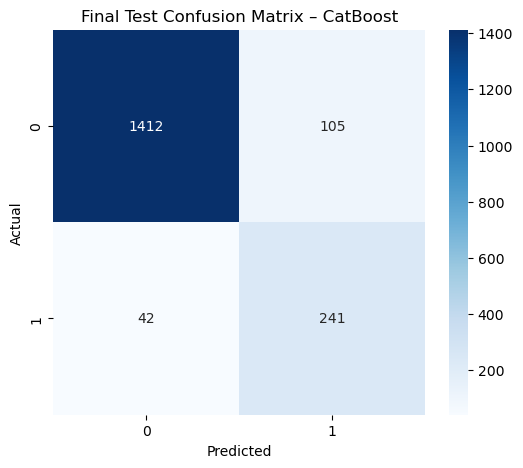

In [350]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    final_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    f"Final Test Confusion Matrix – {selected_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# EARLY-INTENT MODEL RECOMMENDATION

Keep two business interpretations:

### Full-session model
Uses `PageValues`.  
Best for scoring visitors near the end of a shopping session.

### Early-intent model
Excludes `PageValues`.  
Performance will be lower, but it is more realistic when the business wants to intervene earlier in the browsing journey.

The existing PageValues ablation section already demonstrates this trade-off and should remain in the project.


# DEPLOYMENT IMPROVEMENT

The new evaluation pipeline already places `create_features()` inside the sklearn pipeline.

That means the API/dashboard should pass the **17 raw input columns only**.  
The saved pipeline itself should calculate:

- TotalPages
- TotalDuration
- AvgTimePerPage
- ProductEngagementRatio
- ProductTimeRatio
- ReturningVisitorFlag

This avoids training-serving mismatch.


In [353]:
# Save improved deployment artifacts
from pathlib import Path

PROJECT_ROOT = Path.cwd()

IMPROVED_ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
IMPROVED_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Fix pickling issue: replace lambda-based feature_names_out with a top-level function
def engineered_feature_names(transformer, names):
    return create_features(pd.DataFrame(columns=list(names))).columns.tolist()

selected_model_safe = Pipeline([
    (
        "feature_engineering",
        FunctionTransformer(
            func=create_features,
            validate=False,
            feature_names_out=engineered_feature_names
        )
    ),
    ("preprocessor", selected_model.named_steps["preprocessor"]),
    ("model", selected_model.named_steps["model"])
])

# keep the safe pipeline in memory for later use
selected_model = selected_model_safe

joblib.dump(
    selected_model,
    IMPROVED_ARTIFACT_DIR / "purchase_intent_model_improved.joblib"
)

joblib.dump(
    calibrator,
    IMPROVED_ARTIFACT_DIR / "probability_calibrator.joblib"
)

joblib.dump(
    FINAL_CALIBRATED_THRESHOLD,
    IMPROVED_ARTIFACT_DIR / "decision_threshold_improved.joblib"
)

print("Improved artifacts saved to:")
print(IMPROVED_ARTIFACT_DIR.resolve())


Improved artifacts saved to:
D:\Poonam Docs\Internmo\E-Commerce\E-Commerce Purchase Intent Prediction\artifacts


# FINAL CONCLUSION

The original analysis showed strong offline purchase-intent prediction, with CatBoost performing best among the six candidate algorithms.

The improved evaluation now separates model development into training, validation, and a completely untouched final test set. Model selection, probability calibration, and decision-threshold tuning are performed only on the validation data. Therefore, the final test metrics produced above are more defensible estimates of real-world generalization.

`PageValues` remains the dominant predictive feature. The existing ablation analysis demonstrates that removing it substantially reduces model performance, so the project should distinguish between a high-performing full-session model and a more realistic early-intent model that excludes late-stage purchase signals.

For deployment, feature engineering is now embedded inside the model pipeline, reducing the risk of inconsistent calculations between the notebook, FastAPI service, and Streamlit dashboard.

Future production work should focus on temporal validation, model-drift monitoring, periodic retraining, and adding richer customer-history, cart, campaign, and product-interaction features.
